## 3. Text Classification (Using Classical Machine Learning)

In [ ]:
import warnings
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
from training import *
from preprocessing import *
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

### 3.1 EDA & preprocessing

In [ ]:

dataset = load_dataset("stanfordnlp/imdb")
train, test = dataset["train"], dataset["test"]


train_texts = train["text"]
train_labels = train["label"]  # 0 = negative; 1 = positive


In [ ]:
train = train.to_pandas()
test = test.to_pandas()

#### 3.1.1. Labels distribution

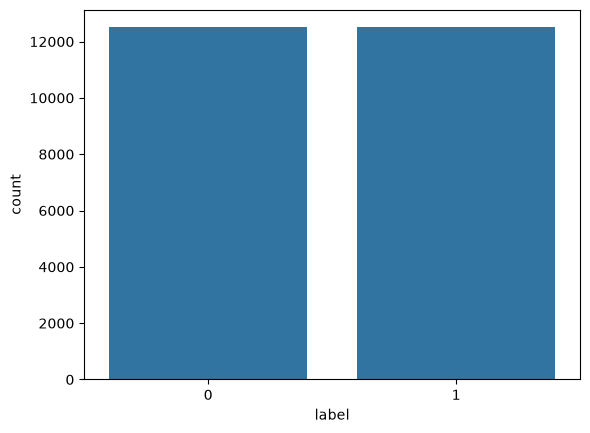

In [ ]:
# Labels distribution - train

sns.countplot(train, x = 'label')
plt.show()

In [92]:
train['label'].value_counts()

label
0    12500
1    12500
Name: count, dtype: int64

In [ ]:
# Checking missing values in the test set
test['label'].value_counts()

label
0    12500
1    12500
Name: count, dtype: int64

#### 3.1.2. Reviews overview

In [49]:
# Length of reviews (sum of all characters)

In [99]:
train['Length'] = [len(x) for x in train['text']]

In [104]:
train.describe()

,label,Length
count,25000.00000,25000.00000
mean,0.50000,1325.06964
std,0.50001,1003.13367
min,0.00000,52.00000
25%,0.00000,702.00000
50%,0.50000,979.00000
75%,1.00000,1614.00000
max,1.00000,13704.00000


In [103]:
# Length's distribution per label

fig = px.histogram(train, x = 'Length', color = 'label')
fig.show()

In [105]:
# Length's distribution per label

fig_2 = px.box(train, x = 'Length', color = 'label')
fig_2.show()

In [106]:
# Checking for unusual characters

In [116]:
idx = random.sample(range(len(train)), 20)

for i in idx:
    print(f'Rev {i}:', train.iloc[i]['text'])

Rev 11029: I was never so bored in my life. Hours of pretentious, self-obsessed heroin-addicted basket cases lounging around whining about their problems. It's like watching lizards molt. Even the sex scenes will induce a serious case of narcolepsy. If you have insomnia, rent this.
Rev 3349: I am a huge horror/splatter fan, I even enjoy horror films some people consider as stupid. I also like gore. The more the merrier as long as it has a point.<br /><br />After reading the other people's reviews on the site I was sure this film was going to be a little gem. But much to my disappointment it proved to be one of the most pointless films I've ever watched.<br /><br />The acting was terrible, the dialogs were stupid, the plot was pointless, the special effects were useless and the editing was probably done by someone who has been dead for the past 2 years. Usually i find that all these characteristics make a great b horror movie . But not in this case.<br /><br />I waisted 11 EUR to get th

#### 3.1.3. Preprocessing pipeline

In [7]:
pipe_1 = Pipeline([
    ('normal', NormalizationTransformer()),
    ('stop', StopremovalTransformer()),
    ('lemm', LemmaTransformer())
    
])

In [8]:
# Training set preprocessing
X = pipe_1.fit_transform(train.text)

# Testing set preprocessing
X_t = pipe_1.fit_transform(test.text)

Normalization
Stop words removal
Lemmatization
Completed
Normalization
Stop words removal
Lemmatization
Completed


#### 3.1.4. Checking word frequencies

In [105]:
freq_total = freq(X)
freq_pos = freq(X[train['label']==1])
freq_neg = freq(X[train['label']==0])


In [106]:
freq_total.head(20)

,Word,Frequency
0,movie,51540
1,film,46951
2,one,27687
3,like,20668
4,time,15907
5,good,15150
6,character,14147
7,story,13144
8,even,12615
9,get,12505


In [107]:
freq_pos.head(20)

,Word,Frequency
0,film,24694
1,movie,22581
2,one,14138
3,like,9227
4,time,8316
5,good,7731
6,story,7461
7,character,7048
8,well,6495
9,great,6417


In [108]:
freq_neg.head(20)

,Word,Frequency
0,movie,28959
1,film,22257
2,one,13549
3,like,11441
4,even,7667
5,time,7591
6,good,7419
7,bad,7375
8,character,7099
9,would,6900


#### 3.1.4. Checking distributions of lengths after tokenization

In [59]:
lengths = X.apply(lambda x: len(x.split()))
lengths = pd.DataFrame({
    'Length': lengths,
    'label': train['label']
})

In [60]:
lengths[["Length"]].describe()

,Length
count,25000.000000
mean,121.970520
std,92.197232
min,4.000000
25%,65.000000
50%,90.000000
75%,149.000000
max,1436.000000


In [119]:
# Length's distribution per label

fig = px.histogram(lengths, x = 'Length', color = 'label')
fig.show()

In [120]:
# Length's distribution per label

fig_2 = px.box(lengths, x = 'Length', color = 'label')
fig_2.show()

In [61]:
len(lengths[lengths['Length']>266])/len(lengths)

0.0786

In [62]:
len(lengths[lengths['Length']>600])/len(lengths)

0.00084

In [66]:
len(lengths[lengths['Length']<20])/len(lengths)

0.00552

#### 3.1.5. EDA & preprocessing conclusions

Conclusions - EDA
* Reviews contain both upper and lower letters
* Reviews contain special characters, such as: < > / . , ( ) ' \
* Reviews contain HTML syntax, such as <br />
* Reviews contain special characters as word separators, such as 'self-obsessed' or 'heroin-addicted'
* Both train and test datasets are balanced, with similar ratio of positive vs negative reviews
* Distrbutions of reviews' length are alike for both labels, right-skewed: 
    * Count of long reviews is not significant - ~8% for reviews longer than 400 tokens, and ~0% for reviews longer than 600 tokens
    * Count of short reviews is not significant - ~1% for reviews shorter than 20 tokens
    * This distribution is reasonable and may be a standard for online reviews - people prefer to write rather shorter opinions
* There are no missing labels
* Most common words:
    * In total, most common sentiment-specific words are "good" and "bad", with "bad" being at the bottom of the list
    * For positive reviews, there are words like "good", "great", "well" in top 20 most common words. Word "bad" is not included in top 20
    * For negative reviews, "bad" is in top 10 and "dont" can be also observed


Conclusions - preprocessing
* Preprocessing included following steps:
    * Converion to lowercase
    * Replacing special symbols between words by space, to capture both words 
    * Replacing HTML syntax by space, to capture adjacent words
    * Removing punctuation 
    * Removing numbers
    * Removing stop words
    * Lemmatization to capture actual words describing sentiment - more accurate than stemming and enables to capture actual adjectives describing movies, not roots



### 3.2 Vectorization and model optimization

In [12]:
pipe_2 = Pipeline([
    ('vectorizer', TfidfVectorizer()),
    ('model', MultinomialNB())
])

##### 3.2.1 Train - validation split

In [18]:
X_train, X_val, y_train, y_val  = train_test_split(X, train['label'], test_size=0.2, random_state=42)

##### 3.2.2 Baseline predictions

In [40]:
# Validation set
pipe_2.fit(X_train, y_train)
pred_val = pipe_2.predict(X_val)
score_base_val = classification_report(y_val, pred_val, digits=4)

In [ ]:
pipe_2

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vectorizer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


In [41]:
print(score_base_val)

              precision    recall  f1-score   support

           0     0.8603    0.8740    0.8671      2515
           1     0.8703    0.8563    0.8633      2485

    accuracy                         0.8652      5000
   macro avg     0.8653    0.8651    0.8652      5000
weighted avg     0.8653    0.8652    0.8652      5000



In [42]:
# Test set
pipe_2.fit(X, train['label'])
pred_test = pipe_2.predict(X_t)
score_base_test = classification_report(test['label'], pred_test, digits=4)

In [43]:
print(score_base_test)

              precision    recall  f1-score   support

           0     0.7981    0.8829    0.8383     12500
           1     0.8690    0.7766    0.8202     12500

    accuracy                         0.8298     25000
   macro avg     0.8335    0.8298    0.8293     25000
weighted avg     0.8335    0.8298    0.8293     25000



##### 3.2.3 Optimization

In [81]:
# Training and optimizing the model using cross validation and checking performance on validation set

results = optimize_model(200, X_train, X_val, y_train, y_val)


Optimizing
Evaluating


In [82]:
print(results['score'])

              precision    recall  f1-score   support

           0     0.8561    0.8755    0.8657      2515
           1     0.8711    0.8511    0.8610      2485

    accuracy                         0.8634      5000
   macro avg     0.8636    0.8633    0.8634      5000
weighted avg     0.8636    0.8634    0.8634      5000



In [83]:
results['params']

{'max_features': 19534, 'alpha': 0.984797901012127}

### 3.3 Prediction of the test set and evaluation

In [84]:
results_test = predict_test(results['params'], X, train['label'], X_t, test['label'])

In [85]:
print(results_test['score'])

              precision    recall  f1-score   support

           0     0.8047    0.8788    0.8401     12500
           1     0.8665    0.7867    0.8247     12500

    accuracy                         0.8328     25000
   macro avg     0.8356    0.8328    0.8324     25000
weighted avg     0.8356    0.8328    0.8324     25000



In [ ]:
print(score_base_test)

              precision    recall  f1-score   support

           0     0.7981    0.8829    0.8383     12500
           1     0.8690    0.7766    0.8202     12500

    accuracy                         0.8298     25000
   macro avg     0.8335    0.8298    0.8293     25000
weighted avg     0.8335    0.8298    0.8293     25000



### 3.4 Conclusions

* Test scores improved after optimizing the model
* Best model has TF-IDF Vectorizer set up to  19,534 max features rather than originally fitted 76,000 features
* Preprocessing has impact on vocabulary created by vectorizer:
    * Depending on whether stemming or lemmatization is used, results may differ
    * Text cleaning may have impact on both vocabulary and model performance, e.g. if some cleaning was missed and some words merged or vanished
* Removing stopwords should not have impact on performance, since those are common words and should not have been impactful after vectorizing. However, in some cases it may be useful to leave stopwords, e.g. in case an opinion is "not bad" or "not good". After removing "not" it may be unclear if the sentiment was positive or negative, but if the dataset and feature set are big enough, model should still learn properly
* Model performance does not indicate bias towards a specific class, as the dataset is well balanced